# Exercise 11.3

Apply one-step semi-gradient Q-learning to Baird’s counterexample and show empirically that its weights diverge.

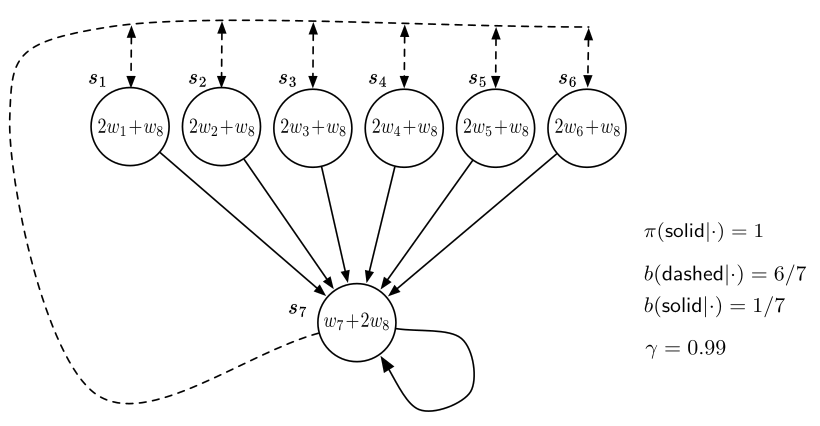

### Equations
We only have features for states and not for actions, so we need to define $\hat{q}$ in terms of $\hat{v}$

* $\displaystyle \hat{q}(\cdot, \text{solid}, \mathbf{w}) = \gamma \hat{v}(s_7, \mathbf{w})$
* $\displaystyle \hat{q}(\cdot, \text{dashed}, \mathbf{w}) = \frac{\gamma}{6} \sum_{i=1}^{6} \hat{v}(s_i, \mathbf{w})$

Therefore

* $\displaystyle \nabla \hat{q}(\cdot, \text{solid}, \mathbf{w}) = \gamma \mathbf{x}(s_7)$
* $\displaystyle \nabla \hat{q}(\cdot, \text{dashed}, \mathbf{w}) = \frac{\gamma}{6} \sum_{i=1}^{6} \mathbf{x}(s_i)$

In [135]:
import numpy as np
import matplotlib.pyplot as plt

In [136]:
class BairdsEnv:
    def __init__(self, gamma=0.99):
        self.states = [
            (2, 0, 0, 0, 0, 0, 0, 1),
            (0, 2, 0, 0, 0, 0, 0, 1),
            (0, 0, 2, 0, 0, 0, 0, 1),
            (0, 0, 0, 2, 0, 0, 0, 1),
            (0, 0, 0, 0, 2, 0, 0, 1),
            (0, 0, 0, 0, 0, 2, 0, 1),
            (0, 0, 0, 0, 0, 0, 1, 2),
        ]
        self.n_states = len(self.states)

        self.actions = [
            "solid",
            "dashed"
        ]

        self.gamma = 0.99

    
    def step(self, state, action):
        if action == "solid":
            next_state = 6
        else:
            next_state = np.random.choice(np.arange(self.n_states - 1)).item()

        return next_state, 0.0

    def approximate_v(self, state, w):
        features = np.array(self.states[state])
        return np.dot(w, features).item()

    def approximate_q(self, state, action, w):
        if action == "solid":
            return self.gamma * self.approximate_v(self.n_states - 1, w)
        else:
            next_states_v = [self.approximate_v(s, w) for s in range(self.n_states - 1)]
            return self.gamma * np.mean(next_states_v).item()

    def gradient_q(self, state, action):
        if action == "solid":
            return self.gamma * np.array(self.states[self.n_states - 1])
        else:
            next_states_features = [np.array(self.states[s]) for s in range(self.n_states - 1)]
            return self.gamma * np.mean(next_states_features, axis=0)
            


In [137]:
def epsilon_greedy_policy(env, state, w, epsilon=0.1):
    if np.random.rand() < epsilon:
        return np.random.choice(list(env.actions))
    else:
        q_values = {action: env.approximate_q(state, action, w) for action in env.actions}
        return max(q_values, key=q_values.get)

def b_policy(env, state, w):
    return np.random.choice(["solid", "dashed"], p=[1/7, 6/7]).item()

### Q-Learning loop

In [152]:
alpha = 0.01
n_steps = 10000

env = BairdsEnv()

w = np.array([1, 1, 1, 1, 1, 1, 10, 1], dtype=np.float32)

state = np.random.choice(np.arange(env.n_states)).item()
action = b_policy(env, state, w)

w_history = [
    w.copy()
]

for _ in range(n_steps):
    next_state, reward = env.step(state, action)
    next_action = b_policy(env, next_state, w)

    error = reward + env.gamma * np.max([env.approximate_q(next_state, a, w) for a in env.actions]) - env.approximate_q(state, action, w)

    w = w + alpha * error * env.gradient_q(state, action)

    state = next_state
    action = next_action

    w_history.append(w.copy())

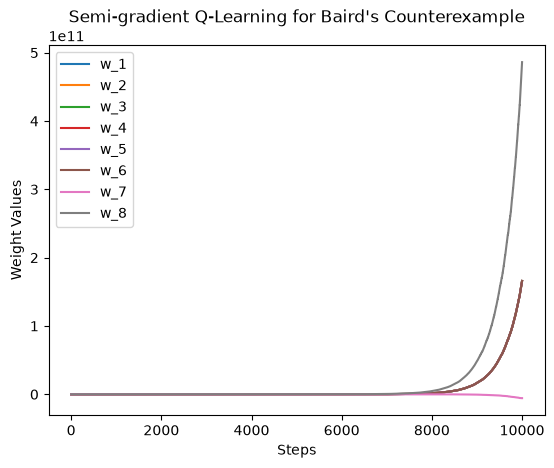

In [153]:
plt.plot(np.array(w_history), label=[f'w_{i+1}' for i in range(len(w))])
plt.legend()
plt.xlabel('Steps')
plt.ylabel('Weight Values')
plt.title('Semi-gradient Q-Learning for Baird\'s Counterexample')
plt.show()

In [154]:
# Approximate state values for each state using the learned weights

for i in range(env.n_states):
    print(f"V(s_{i+1}) = {env.approximate_v(i, w):.4f}")

V(s_1) = 817829459961.0123
V(s_2) = 817829459961.0123
V(s_3) = 817829459961.0123
V(s_4) = 817829459961.0123
V(s_5) = 817829459961.0123
V(s_6) = 817829459961.0123
V(s_7) = 966634355390.9707


### Sarsa loop (for comparison)

In [155]:
alpha = 0.01
n_steps = 100000

env = BairdsEnv()

w = np.array([1, 1, 1, 1, 1, 1, 10, 1], dtype=np.float32)

state = np.random.choice(np.arange(env.n_states)).item()
action = b_policy(env, state, w)

w_history = [
    w.copy()
]

for _ in range(n_steps):
    next_state, reward = env.step(state, action)
    next_action = b_policy(env, next_state, w)

    error = reward + env.gamma * env.approximate_q(next_state, next_action, w) - env.approximate_q(state, action, w)

    w = w + alpha * error * env.gradient_q(state, action)

    state = next_state
    action = next_action

    w_history.append(w.copy())

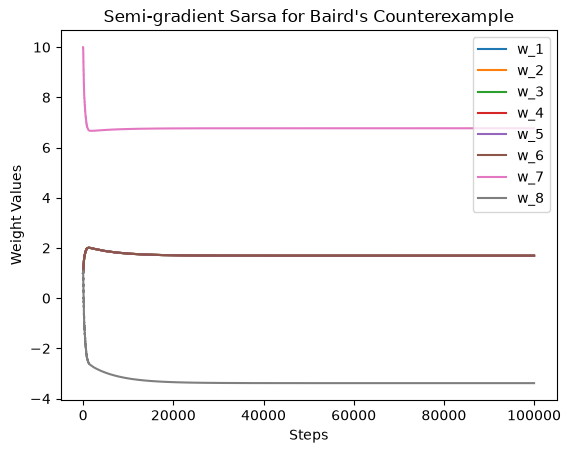

In [156]:
plt.plot(np.array(w_history), label=[f'w_{i+1}' for i in range(len(w))])
plt.legend()
plt.xlabel('Steps')
plt.ylabel('Weight Values')
plt.title('Semi-gradient Sarsa for Baird\'s Counterexample')
plt.show()

In [157]:
# Approximate state values for each state using the learned weights

for i in range(env.n_states):
    print(f"V(s_{i+1}) = {env.approximate_v(i, w):.4f}")

V(s_1) = 0.0000
V(s_2) = 0.0000
V(s_3) = 0.0000
V(s_4) = 0.0000
V(s_5) = 0.0000
V(s_6) = 0.0000
V(s_7) = 0.0000
